In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import warnings
import pandas as pd
import pickle
import time
import os
import matplotlib

In [2]:
from cell import cell
tau_vec = [24,30,40]
max_size=200

def find_tot_plasmids(y1,max_size):
    y1[0]+=y1[1]   #because of plasmid shedding y[1] may have a nonzero value, we transfer this to y[0].
    y1[1]=y1[0]
    y_tot = np.dot(np.arange(1,max_size),y1[1:max_size])
    return y_tot 

def collect_inheritance(cells):
    inheritance = []
    for idx in range(len(cells)):
        focus = cells[idx]
        inheritance = np.append(inheritance,[focus.x[0]])         
    return inheritance

def collect_inherit_poles(cells):
    pole1 = []
    pole2 = []
    for idx in np.arange(1,len(cells)):
        focus = cells[idx].fin_clusters
        pole1.append(find_tot_plasmids(focus[:max_size],max_size))
        pole2.append(find_tot_plasmids(focus[max_size:],max_size))
        
    return pole1,pole2

In [3]:
inherit_collect = np.zeros([len(tau_vec),1000])
inherit_pole1 = np.zeros([len(tau_vec),1000-1])
inherit_pole2 = np.zeros([len(tau_vec),1000-1])

k=0
for i in tau_vec:
    filename = './growth_vs_asymmetry/tau'+str(i)+'.pkl'
    with open(filename, 'rb') as file:
        cells = pickle.load(file)
    inherit_collect[k,:] = collect_inheritance(cells)
    inherit_pole1[k,:],inherit_pole2[k,:] = collect_inherit_poles(cells)
    k+=1

C:\Users\Jayson Cortez\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\Jayson Cortez\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
C:\Users\Jayson Cortez\anaconda3\Lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


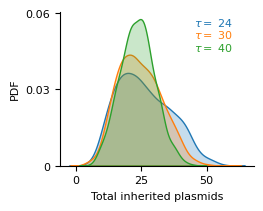

In [4]:
f=plt.figure(figsize=(2.5,2))
ax = f.add_subplot(111)
sns.kdeplot(inherit_collect[0,:],fill=True,ax=ax)
sns.kdeplot(inherit_collect[1,:],fill=True,ax=ax)
sns.kdeplot(inherit_collect[2,:],fill=True,ax=ax)
ax.set_xlabel('Total inherited plasmids',fontsize=8)
ax.set_xticks([0,25,50])
ax.set_xticklabels([0,25,50],fontsize=8)
ax.set_yticks([0,0.03,0.06])
ax.set_yticklabels([0,0.03,0.06],fontsize=8)
ax.text(45,0.055,r'$\tau=$ %d' %(tau_vec[0]),fontsize=8,color='C0')
ax.text(45,0.05,r'$\tau=$ %d' %(tau_vec[1]),fontsize=8,color='C1')
ax.text(45,0.045,r'$\tau=$ %d' %(tau_vec[2]),fontsize=8,color='C2')
ax.set_ylabel('PDF',fontsize=8)
sns.despine()

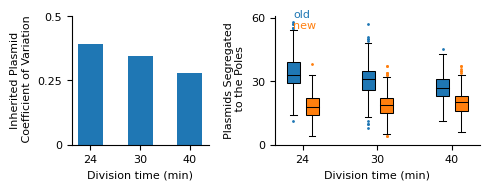

In [62]:
def box_plot(data, edge_color, fill_color,pos,out_color):
    bp = axes[1].boxplot(data, patch_artist=True,positions=pos,showfliers=True,widths=0.35,sym=out_color)
    for element in ['boxes', 'whiskers', 'fliers', 'means', 'medians', 'caps']:
        plt.setp(bp[element], color=edge_color, linewidth=0.75)
    for patch in bp['boxes']:
        patch.set(facecolor=fill_color)       
    plt.setp(bp['fliers'], color=edge_color, linewidth=0.25,markersize=1)
    return bp

f,axes=plt.subplots(1,2,figsize=(5,2),width_ratios=[1, 1.5])
#ax = f.add_subplot(111)
cv1 = np.std(inherit_collect[0,:])/np.mean(inherit_collect[0,:])
cv2 = np.std(inherit_collect[1,:])/np.mean(inherit_collect[1,:])
cv3 = np.std(inherit_collect[2,:])/np.mean(inherit_collect[2,:])

axes[0].bar([1,1.5,2],[cv1,cv2,cv3],color=['C0','C0','C0'],width=0.25)
axes[0].set_ylabel('Inherited Plasmid\n Coefficient of Variation',fontsize=8)
axes[0].set_xticks([1,1.5,2])
axes[0].set_xticklabels(tau_vec,fontsize=8)
axes[0].set_yticks([0,0.25,0.5])
axes[0].set_yticklabels([0,0.25,0.5],fontsize=8)
axes[0].set_xlabel(r'Division time (min)',fontsize=8)


beta1_old = box_plot(inherit_pole1[0,:], 'k', 'C0',[1], 'C0')
beta1_new = box_plot(inherit_pole2[0,:], 'k', 'C1',[1.5], 'C1')
beta2_old = box_plot(inherit_pole1[1,:], 'k', 'C0',[3], 'C0')
beta2_new = box_plot(inherit_pole2[1,:], 'k', 'C1',[3.5], 'C1')
beta3_old = box_plot(inherit_pole1[2,:], 'k', 'C0',[5], 'C0')
beta3_new = box_plot(inherit_pole2[2,:], 'k', 'C1',[5.5], 'C1')
axes[1].set_xticks([1.25,3.25,5.25])
axes[1].set_xticklabels(tau_vec,fontsize=8)
axes[1].set_yticks([0,30,60])
axes[1].set_yticklabels([0,30,60],fontsize=8)

axes[1].set_xlabel(r'Division time (min)',fontsize=8)
axes[1].set_ylabel('Plasmids Segregated\n to the Poles',fontsize=8)
axes[1].text(1,60,'old',color='C0',fontsize=8)
axes[1].text(1,55,'new',color='C1',fontsize=8)

#ax.legend()
sns.despine()
plt.tight_layout(h_pad=1)

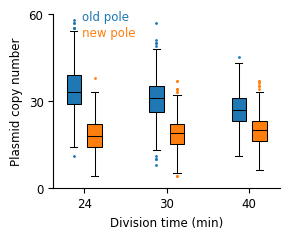

In [4]:
import matplotlib

def box_plot(data, edge_color, fill_color,pos,out_color):
    bp = ax.boxplot(data, patch_artist=True,positions=pos,showfliers=True,widths=0.35,sym=out_color)
    for element in ['boxes', 'whiskers', 'fliers', 'means', 'medians', 'caps']:
        plt.setp(bp[element], color=edge_color, linewidth=0.75)
    for patch in bp['boxes']:
        patch.set(facecolor=fill_color)       
    plt.setp(bp['fliers'], color=edge_color, linewidth=0.25,markersize=1)
    return bp

f =plt.figure(figsize=(3,2.5))
ax = f.add_subplot(111)
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
fontsiz=8.5

beta1_old = box_plot(inherit_pole1[0,:], 'k', 'C0',[1], 'C0')
beta1_new = box_plot(inherit_pole2[0,:], 'k', 'C1',[1.5], 'C1')
beta2_old = box_plot(inherit_pole1[1,:], 'k', 'C0',[3], 'C0')
beta2_new = box_plot(inherit_pole2[1,:], 'k', 'C1',[3.5], 'C1')
beta3_old = box_plot(inherit_pole1[2,:], 'k', 'C0',[5], 'C0')
beta3_new = box_plot(inherit_pole2[2,:], 'k', 'C1',[5.5], 'C1')
ax.set_xticks([1.25,3.25,5.25])
ax.set_xticklabels(tau_vec,fontsize=fontsiz)
ax.set_yticks([0,30,60])
ax.set_yticks([0,30,60])
ax.set_ylim([0,60])

ax.set_yticklabels([0,30,60],fontsize=fontsiz)

ax.set_xlabel(r'Division time (min)',fontsize=fontsiz)
ax.set_ylabel('Plasmid copy number',fontsize=fontsiz)
ax.text(1.2,58,'old pole',color='C0',fontsize=fontsiz)
ax.text(1.2,52.5,'new pole',color='C1',fontsize=fontsiz)

sns.despine()
plt.tight_layout(h_pad=1)

plt.savefig("asymmetry_vs_growth.pdf", format="pdf", bbox_inches="tight")

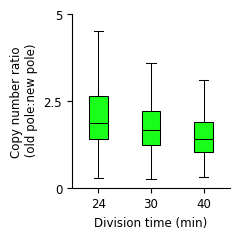

In [5]:
import matplotlib

def box_plot(data, edge_color, fill_color,pos,out_color):
    bp = ax.boxplot(data, patch_artist=True,positions=pos,showfliers=False,widths=0.35,sym=out_color)
    for element in ['boxes', 'whiskers', 'fliers', 'means', 'medians', 'caps']:
        plt.setp(bp[element], color=edge_color, linewidth=0.75)
    for patch in bp['boxes']:
        patch.set(facecolor=fill_color)       
    plt.setp(bp['fliers'], color=edge_color, linewidth=0.25,markersize=1)
    return bp

f =plt.figure(figsize=(2.5,2.5))
ax = f.add_subplot(111)
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
fontsiz=8.5
col = ["#1AFF1A","#4B0092"]
g1 = box_plot(inherit_pole1[0,:]/inherit_pole2[0,:], 'k', col[0],[1], 'C0')
g2 = box_plot(inherit_pole1[1,:]/inherit_pole2[1,:], 'k', col[0],[2], 'C0')
g3 = box_plot(inherit_pole1[2,:]/inherit_pole2[2,:], 'k', col[0],[3], 'C0')

ax.set_xticklabels(tau_vec,fontsize=fontsiz)
ax.set_yticks([0,2.5,5])
ax.set_yticklabels([0,2.5,5],fontsize=fontsiz)
ax.set_xlabel(r'Division time (min)',fontsize=fontsiz)
ax.set_ylabel('Copy number ratio\n (old pole:new pole)',fontsize=fontsiz)
#ax.text(1.2,58,'old pole',color='C0',fontsize=fontsiz)
#ax.text(1.2,52.5,'new pole',color='C1',fontsize=fontsiz)

sns.despine()
plt.tight_layout(h_pad=1)

plt.savefig("asymmetry_vs_growth.pdf", format="pdf", bbox_inches="tight")

In [6]:
threshold = 3

for tau, i in zip(tau_vec, range(len(tau_vec))):
    ratios = inherit_pole1[i, :] / inherit_pole2[i, :]
    p = np.mean(ratios >= threshold)
    print(f"tau = {tau:2d}:  P(R >= {threshold}) = {p:.4f}")

tau = 24:  P(R >= 3) = 0.1722
tau = 30:  P(R >= 3) = 0.0941
tau = 40:  P(R >= 3) = 0.0641


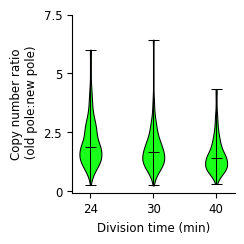

In [3]:
import matplotlib
def violin_plot(data, edge_color, fill_color, pos):
    clip_high = np.percentile(data, 99)  # top 0.5% as cutoff
    data_clipped = np.clip(data, None, clip_high)
    vp = ax.violinplot(
        data_clipped,
        positions=pos,
        widths=0.35,
        showmeans=False,
        showmedians=True,
        showextrema=True
    )

    for body in vp['bodies']:
        body.set_facecolor(fill_color)
        body.set_edgecolor(edge_color)
        body.set_linewidth(0.75)
        body.set_alpha(1)

        # Clip the violin to the actual min/max of your data
        y = body.get_paths()[0].vertices[:, 1]
        y[y < data.min()] = data.min()
        y[y > data.max()] = data.max()
        body.get_paths()[0].vertices[:, 1] = y
        for part in ['cbars', 'cmins', 'cmaxes', 'cmedians']:
            vp[part].set_edgecolor(edge_color)
            vp[part].set_linewidth(0.75)

f = plt.figure(figsize=(2.5, 2.5))
ax = f.add_subplot(111)
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
fontsiz = 8.5
plt.rc('font', size=fontsiz)
col = ["#1AFF1A", "#4B0092"]

g1 = violin_plot(inherit_pole1[0, :] / inherit_pole2[0, :], 'k', col[0], [1])
g2 = violin_plot(inherit_pole1[1, :] / inherit_pole2[1, :], 'k', col[0], [2])
g3 = violin_plot(inherit_pole1[2, :] / inherit_pole2[2, :], 'k', col[0], [3])

ax.set_xticks([1, 2, 3])
ax.set_xticklabels(tau_vec, fontsize=fontsiz)
ax.set_yticks([0, 2.5, 5,7.5])
ax.set_yticklabels([0, 2.5, 5,7.5], fontsize=fontsiz)
ax.set_xlabel(r'Division time (min)', fontsize=fontsiz)
#ax.hlines(1,0.5,3.5)
ax.set_ylabel('Copy number ratio\n (old pole:new pole)', fontsize=fontsiz)
sns.despine()
plt.tight_layout(h_pad=1)
plt.savefig("asymmetry_vs_growth.pdf", format="pdf", bbox_inches="tight")

In [9]:
min(inherit_pole1[0, :] / inherit_pole2[0, :])

0.2894736842105263

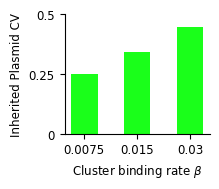

In [17]:
f =plt.figure(figsize=(2.3,2))
ax = f.add_subplot(111)
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
col = ["#1AFF1A","#4B0092"]

cv1 = np.std(inherit_collect[0,:])/np.mean(inherit_collect[0,:])
cv2 = np.std(inherit_collect[1,:])/np.mean(inherit_collect[1,:])
cv3 = np.std(inherit_collect[2,:])/np.mean(inherit_collect[2,:])

ax.bar([1,1.5,2],[cv1,cv2,cv3],color=[col[0],col[0],col[0]],width=0.25)
ax.set_ylabel('Inherited Plasmid CV',fontsize=fontsiz)
ax.set_xticks([1,1.5,2])
ax.set_xticklabels(beta_vec,fontsize=fontsiz)
ax.set_yticks([0,0.25,0.5])
ax.set_yticklabels([0,0.25,0.5],fontsize=fontsiz)
ax.set_xlabel(r'Cluster binding rate $\beta$',fontsize=fontsiz)

sns.despine()
plt.tight_layout()
plt.savefig("inheritance_cv.pdf", format="pdf", bbox_inches="tight")

In [3]:
tau = 24             #30-min doubling time
k_tr = 2.17      
K = 15.2/1.26  
mu = np.log(2)/tau
V0 = 1.2

In [4]:
cp = [44,50,56]
inherit_collect = np.zeros([len(cp),5000])
inherit_pole1 = np.zeros([len(cp),5000-1])
inherit_pole2 = np.zeros([len(cp),5000-1])

k=0
for i in cp:
    filename = './fixed_time/cp'+str(i)+'.pkl'
    with open(filename, 'rb') as file:
        cells = pickle.load(file)
    inherit_collect[k,:] = collect_inheritance(cells)
    inherit_pole1[k,:],inherit_pole2[k,:] = collect_inherit_poles(cells)
    k+=1

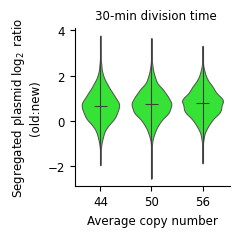

In [5]:
ratio = [
    inherit_pole1[0,:] / inherit_pole2[0,:],
    inherit_pole1[1,:] / inherit_pole2[1,:],
    inherit_pole1[2,:] / inherit_pole2[2,:]
]

log2_ratio = [
    np.log2(inherit_pole1[0, :]) - np.log2(inherit_pole2[0, :]),
    np.log2(inherit_pole1[1, :]) - np.log2(inherit_pole2[1, :]),
    np.log2(inherit_pole1[2, :]) - np.log2(inherit_pole2[2, :])
]

df = pd.DataFrame({
    "Ratio": np.concatenate(log2_ratio),
    "Copy number": np.repeat(cp, [len(r) for r in ratio])
})

# Plot
f, ax = plt.subplots(figsize=(2.5,2.5))

matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42

fontsiz = 8.5
col = "#1AFF1A"

sns.violinplot(
    data=df,
    x="Copy number",
    y="Ratio",
    color=col,
    inner=None,
    cut=0,
    bw_adjust=0.4,
    density_norm="width",   # use scale='width' if using seaborn <0.13
    linewidth=0.75,
    ax=ax
)

for i, vals in enumerate(log2_ratio):
    mean = np.mean(vals)
    sd = np.std(vals, ddof=1)
    ax.vlines(i, vals.min(), vals.max(), color='#3f3f3f', linewidth=0.8)
    ax.hlines(mean, i-0.12, i+0.12, color='#3f3f3f', linewidth=0.8)

#ax.set_yticks([0, 2.5, 5])
ax.set_xlabel(r'Average copy number', fontsize=fontsiz)
#ax.set_ylabel('Copy number ratio\n(old pole:new pole)', fontsize=fontsiz)
ax.set_ylabel(r'Segregated plasmid $\log_2$ ratio'  +  '\n(old:new)', fontsize=fontsiz)
ax.tick_params(labelsize=fontsiz)

ax.text(-0.1, 4.5, '30-min division time', fontsize=fontsiz)

sns.despine()
plt.tight_layout()
plt.savefig("asymmetry_vs_copy.pdf", format="pdf", bbox_inches="tight")

In [7]:
import numpy as np
import pandas as pd
from scipy.stats import wasserstein_distance

summary = pd.DataFrame({
    "Average copy number": cp,
    "Mean (log₂ ratio)": [np.mean(v) for v in log2_ratio],
    "SD": [np.std(v, ddof=1) for v in log2_ratio]
})

print(summary.round(4))

labels = ["42", "50", "57"]

for i in range(len(log2_ratio)):
    for j in range(i + 1, len(log2_ratio)):
        w1 = wasserstein_distance(ratio[i], ratio[j])
        print(f"{labels[i]} vs {labels[j]}: W1 distance = {w1:.6f}")

   Average copy number  Mean (log₂ ratio)      SD
0                   44             0.6714  0.7036
1                   50             0.7339  0.6724
2                   56             0.7798  0.6366
42 vs 50: W1 distance = 0.066182
42 vs 57: W1 distance = 0.127048
50 vs 57: W1 distance = 0.065583


In [15]:
tau_vec = [24,30,40]

inherit_collect = np.zeros([len(tau_vec),5000])
inherit_pole1 = np.zeros([len(tau_vec),5000-1])
inherit_pole2 = np.zeros([len(tau_vec),5000-1])

k=0
cpp = np.zeros(5000)
for i in tau_vec:
    filename = './fixed_cp/tau'+str(i)+'.pkl'
    with open(filename, 'rb') as file:
        cells = pickle.load(file)
    #if i==30:
    #    for jj in range(len(cells)):
    #        print(cells[jj].x[-1])
    #        cpp[jj] = cells[jj].x[-1]
    inherit_collect[k,:] = collect_inheritance(cells)
    inherit_pole1[k,:],inherit_pole2[k,:] = collect_inherit_poles(cells)
    k+=1

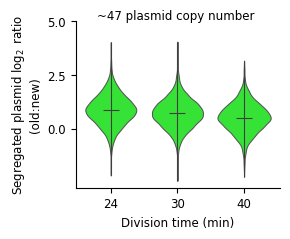

In [16]:
f =plt.figure(figsize=(3,2.5))
ax = f.add_subplot(111)
matplotlib.rcParams['pdf.fonttype'] = 42
matplotlib.rcParams['ps.fonttype'] = 42
fontsiz=8.5
fontsiz = 8.5
col = "#1AFF1A"

ratio = [
    inherit_pole1[0,:] / inherit_pole2[0,:],
    inherit_pole1[1,:] / inherit_pole2[1,:],
    inherit_pole1[2,:] / inherit_pole2[2,:]
]

log2_ratio = [
    np.log2(inherit_pole1[0, :]) - np.log2(inherit_pole2[0, :]),
    np.log2(inherit_pole1[1, :]) - np.log2(inherit_pole2[1, :]),
    np.log2(inherit_pole1[2, :]) - np.log2(inherit_pole2[2, :])
]

div_time = [24,30,40]
df = pd.DataFrame({
    "Ratio": np.concatenate(log2_ratio),
    "Division time (min)": np.repeat(div_time, [len(r) for r in ratio])
})

sns.violinplot(
    data=df,
    x="Division time (min)",
    y="Ratio",
    color=col,
    inner=None,
    cut=0,
    bw_adjust=0.4,
    density_norm="width",   # use scale='width' if using seaborn <0.13
    linewidth=0.75,
    ax=ax
)

for i, vals in enumerate(log2_ratio):
    mean = np.mean(vals)
    sd = np.std(vals, ddof=1)
    ax.vlines(i, vals.min(), vals.max(), color='#3f3f3f', linewidth=0.8)
    ax.hlines(mean, i-0.12, i+0.12, color='#3f3f3f', linewidth=0.8)


ax.set_xticklabels(tau_vec,fontsize=fontsiz)
ax.set_yticks([0,2.5,5])
ax.set_ylabel(r'Segregated plasmid $\log_2$ ratio'  +  '\n(old:new)', fontsize=fontsiz)
ax.set_xlabel("Division time (min)",fontsize=fontsiz)
ax.tick_params(labelsize=fontsiz)
ax.text(-0.2,5.1,'~47 plasmid copy number',color='k',fontsize=fontsiz)
sns.despine()
plt.tight_layout(h_pad=1)
plt.savefig("asymmetry_vs_time.pdf", format="pdf", bbox_inches="tight")

In [17]:
import numpy as np
import pandas as pd
from scipy.stats import wasserstein_distance

summary = pd.DataFrame({
    "Division time": div_time,
    "Mean (log₂ ratio)": [np.mean(v) for v in log2_ratio],
    "SD": [np.std(v, ddof=1) for v in log2_ratio]
})

print(summary.round(4))

labels = ["24", "30", "40"]

for i in range(len(log2_ratio)):
    for j in range(i + 1, len(log2_ratio)):
        w1 = wasserstein_distance(ratio[i], ratio[j])
        print(f"{labels[i]} vs {labels[j]}: W1 distance = {w1:.6f}")

   Division time  Mean (log₂ ratio)      SD
0             24             0.8709  0.7035
1             30             0.7121  0.6838
2             40             0.5133  0.6795
24 vs 30: W1 distance = 0.226991
24 vs 40: W1 distance = 0.469969
30 vs 40: W1 distance = 0.243136
